# PFNS parametric unfolding on the IAEA Compendium benchmark

This notebook applies the **PFNS parametric** unfolding method (`unfold_pfns_parametric`) to a realistic benchmark: detector readings synthesised from the Monte-Carlo calculated spectrum `t4-14-s.txt_1` of the [IAEA Compendium](https://www-nds.iaea.org/benchmarks/).

The spectrum is represented by one of four analytical prompt-fission neutron spectrum families from Jovančević et al. (2026) � Maxwellian, Watt, Koçak (Eq. 16) and Mannhart-based � and the family parameters are fitted to the measured activation readings by nonlinear least squares. All four families are compared below.

We use the built-in GSF response functions (10 Bonner spheres, `0in` � `18in`, 60 energy bins). Detector readings are folded with `Detector.get_effective_readings_for_spectra`; the ground truth never enters the unfolding.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bssunfold import Detector, RF_GSF
from bssunfold.utils.comparison import compare_spectra

detector = Detector(RF_GSF)
E = detector.E_MeV
names = detector.detector_names
print(f"Detector grid: {detector.n_energy_bins} bins, "
      f"{E[0]:.1e} - {E[-1]:.1f} MeV")
print("Spheres:", ", ".join(names))


Detector grid: 60 bins, 1.0e-09 - 631.0 MeV
Spheres: 0in, 2in, 3in, 5in, 6in, 8in, 10in, 12in, 15in, 18in


## 1. IAEA Compendium reference spectrum -> detector readings

Reference CSV: 61 rows, 20 spectra, 1.0e-09 - 631 MeV


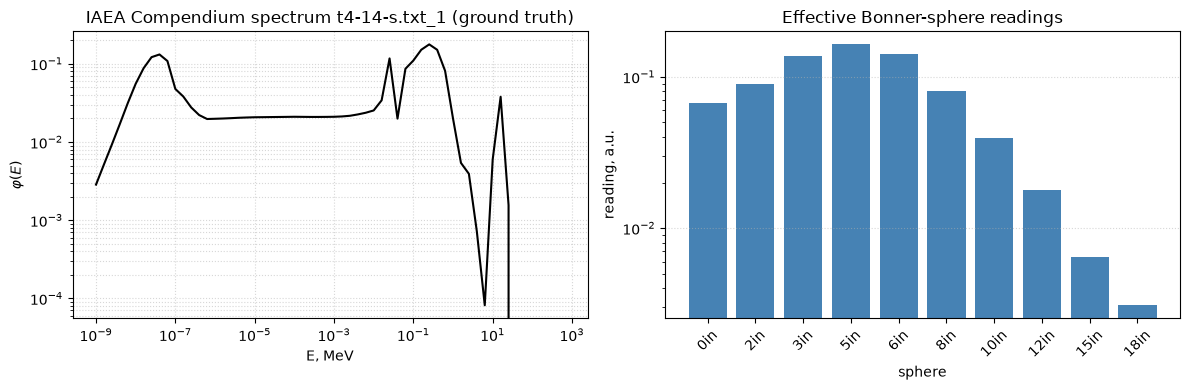

In [2]:
reference_csv = pd.read_csv(
    '../tests/MonteCarlo_Calculated_spectra_from_IAEA_Comp_for_comparison.csv'
)
print(f"Reference CSV: {len(reference_csv)} rows, "
      f"{len(reference_csv.columns) - 1} spectra, "
      f"{reference_csv['E_MeV'].min():.1e} - "
      f"{reference_csv['E_MeV'].max():.0f} MeV")

SPECTRUM = 't4-14-s.txt_1'

readings = detector.get_effective_readings_for_spectra(
    reference_csv[['E_MeV', SPECTRUM]]
)

phi_true = np.interp(
    E, reference_csv['E_MeV'].values, reference_csv[SPECTRUM].values
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.loglog(E, phi_true, 'k-', lw=1.5)
ax.set(xlabel='E, MeV', ylabel=r'$\varphi(E)$',
       title=f'IAEA Compendium spectrum {SPECTRUM} (ground truth)')
ax.grid(True, which='both', ls=':', alpha=0.5)

ax = axes[1]
vals = [readings[nm] for nm in names]
ax.bar(np.arange(len(names)), vals, color='steelblue')
ax.set_yscale('log')
ax.set_xticks(np.arange(len(names)))
ax.set_xticklabels(names, rotation=45)
ax.set(xlabel='sphere', ylabel='reading, a.u.', title='Effective Bonner-sphere readings')
ax.grid(True, axis='y', ls=':', alpha=0.5)
fig.tight_layout()
plt.show()


## 2. Unfold with each PFNS family

Four analytical families are fitted independently. `search='local'` keeps the run fast; `calculate_errors=True` adds Monte-Carlo uncertainty bands.

In [3]:
families = ['maxwellian', 'watt', 'kocak', 'mannhart']
results = {}
for fam in families:
    r = detector.unfold_pfns_parametric(
        readings, family=fam, search='local',
        calculate_errors=True, n_montecarlo=20,
        random_state=0, save_result=False,
    )
    results[fam] = r
    print(f"\n{fam}:")
    print(f"  residual norm : {r['residual_norm']:.3e}")
    print(f"  params        : {r.get('model_params')}")
    m = compare_spectra(phi_true, r['spectrum'],
                        metrics=['relative_flux_error', 'pearson_r',
                                 'comprehensive_score'])
    for k, v in m.items():
        print(f"    {k:<28s}: {v:.3f}")



maxwellian:
  residual norm : 1.713e-01
  params        : {'T': 1.300000000000002, 'scale': 0.1889202104709717, 'family': 'maxwellian', 'search': 'local', 'relative': True}
    relative_flux_error         : 0.771
    pearson_r                   : 0.513
    comprehensive_score         : 0.514

watt:
  residual norm : 1.864e-01
  params        : {'a': 0.9750000000087862, 'b': 2.800000000046683, 'scale': 0.08857619140805507, 'family': 'watt', 'search': 'local', 'relative': True}
    relative_flux_error         : 0.806
    pearson_r                   : 0.461
    comprehensive_score         : 0.575

kocak:
  residual norm : 1.658e-01
  params        : {'T': 1.0000000000000002, 'Ef': 0.48000000000000004, 'k': 0.32000000000000006, 'scale': 0.11335662734966309, 'family': 'kocak', 'search': 'local', 'relative': True}
    relative_flux_error         : 0.760
    pearson_r                   : 0.529
    comprehensive_score         : 0.495

mannhart:
  residual norm : 1.902e-01
  params        : {'

## 3. Comparison of the four families

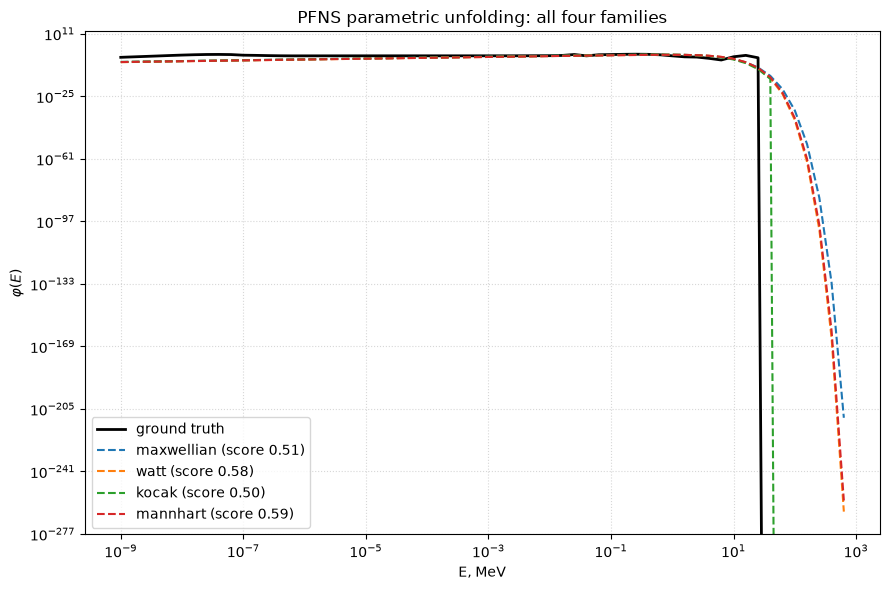

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.loglog(E, phi_true, 'k-', lw=2.0, label='ground truth')
colors = {'maxwellian': 'C0', 'watt': 'C1', 'kocak': 'C2', 'mannhart': 'C3'}
for fam in families:
    r = results[fam]
    ax.loglog(E, r['spectrum'], '--', lw=1.5, color=colors[fam],
              label=f'{fam} (score {compare_spectra(phi_true, r["spectrum"], metrics=["comprehensive_score"])["comprehensive_score"]:.2f})')
ax.set(xlabel='E, MeV', ylabel=r'$\varphi(E)$',
       title='PFNS parametric unfolding: all four families')
ax.legend()
ax.grid(True, which='both', ls=':', alpha=0.5)
fig.tight_layout()
plt.show()


## 4. Monte-Carlo uncertainty bands (Koçak family)

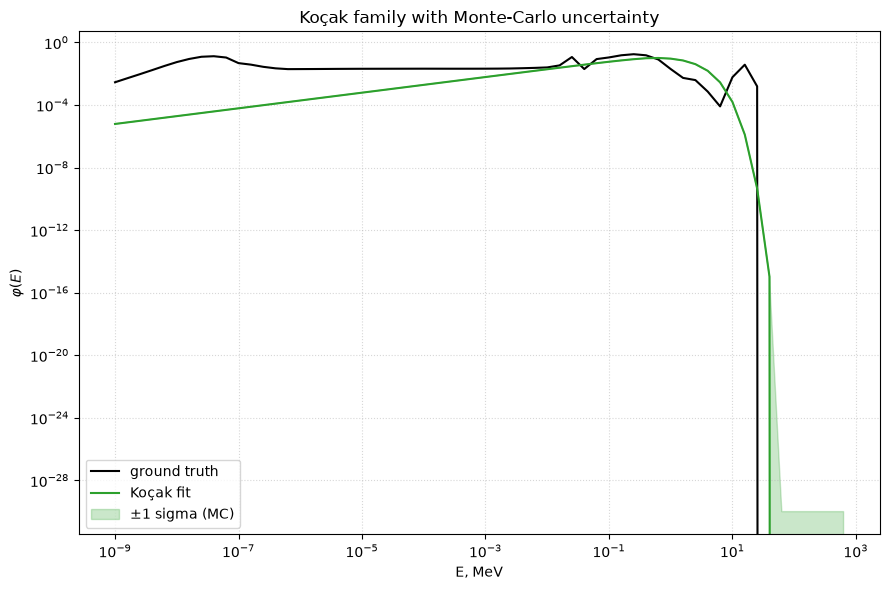

In [5]:
r = results['kocak']
fig, ax = plt.subplots(figsize=(9, 6))
ax.loglog(E, phi_true, 'k-', lw=1.5, label='ground truth')
ax.loglog(E, r['spectrum'], 'C2-', lw=1.5, label='Koçak fit')
if 'spectrum_uncert_std' in r:
    lo = np.maximum(r['spectrum'] - r['spectrum_uncert_std'], 1e-30)
    hi = r['spectrum'] + r['spectrum_uncert_std']
    ax.fill_between(E, lo, hi, color='C2', alpha=0.25, label='±1 sigma (MC)')
ax.set(xlabel='E, MeV', ylabel=r'$\varphi(E)$',
       title='Koçak family with Monte-Carlo uncertainty')
ax.legend()
ax.grid(True, which='both', ls=':', alpha=0.5)
fig.tight_layout()
plt.show()


## 5. Summary

- `unfold_pfns_parametric` represents the spectrum by one of four analytical PFNS families (Maxwellian, Watt, Koçak, Mannhart-based) and fits the family parameters to the readings by nonlinear least squares.
- `family` selects the spectral shape; `search='local'`/`'global'` controls the optimiser.
- Monte-Carlo uncertainties are available via `calculate_errors=True`.
- The Mannhart family uses a Watt(1.025, 2.926) approximation of the Mannhart reference spectrum (the tabulated evaluation is not shipped).